# Auditory Discrimination Task Stimuli

Generates the four stimulus conditions:

| Task | Condition | Tone type | F0 |
|------|-----------|-----------|----|
| Easy (PT) | Go | Pure tone | Alternating 4.5 / 7.9 kHz |
| Easy (PT) | No-Go | Pure tone | Repeating 6 kHz |
| Hard (HCT) | Go | Harmonic complex | Alternating 4.5 / 7.9 kHz |
| Hard (HCT) | No-Go | Harmonic complex | Repeating 6 kHz |

HCT harmonics span F0 up to 50 kHz. Sample rate 192 kHz captures all harmonics accurately.

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
import scipy.signal
from utils.tone_utils import *

In [23]:
# Stimulus parameters
SR           = 192_000   # Hz (captures harmonics up to 96 kHz)
PULSE_DUR    = 0.050     # s  each tone burst (50 ms)
PULSE_INTERVAL = 0.01   # s  inter-pulse gap (10 ms)
PULSE_ONSET  = PULSE_DUR + PULSE_INTERVAL  # s  onset-to-onset
N_PULSES     = 8         # pulses per train
RAMP         = 0.004     # s  4 ms cosine-squared onset/offset ramp
F0_LOW       = 4_547     # Hz Go low F0 (7.917/4.547 kHz = 0.4 oct around 6 kHz)
F0_HIGH      = 7_917     # Hz Go high F0
F0_NOGO      = 6_000     # Hz No-Go F0
HCT_MAX_FREQ = 50_000    # Hz upper harmonic cutoff for HCT
AMPLITUDE    = db_to_amp(60)  # 60 dB SPL for all tones


## Easy task -- Pure Tones (PT)

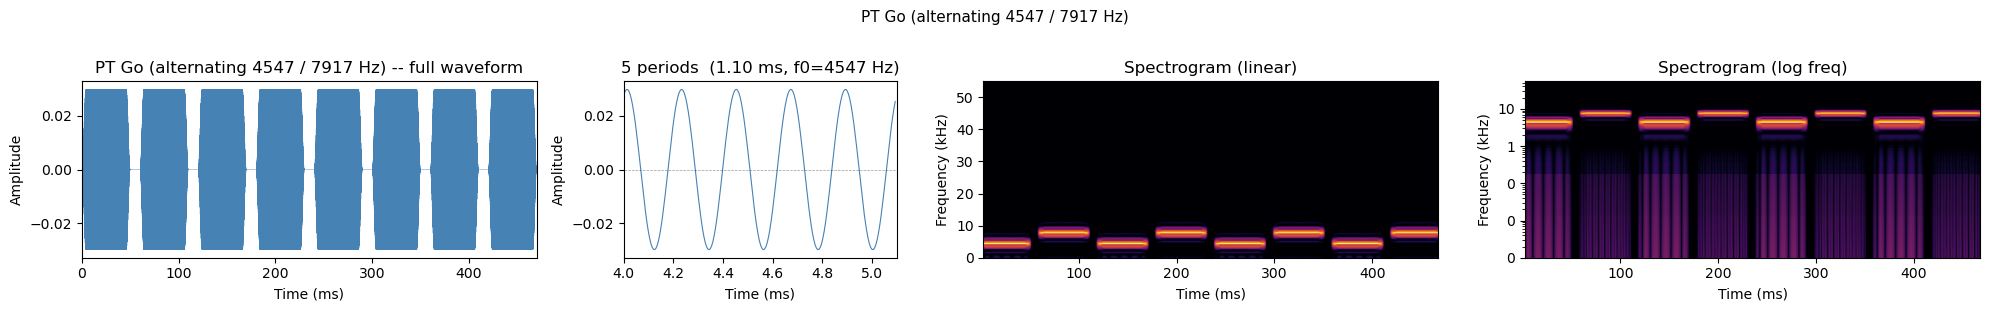

Duration: 470 ms | SR: 192 kHz


In [24]:
# PT Go: alternating pulse train, F0 = 4.5 kHz / 7.9 kHz
pt_go = make_pulse_train([
    lambda: make_pure_tone(F0_LOW, duration=PULSE_DUR, sr=SR, ramp=RAMP, amplitude=AMPLITUDE),
    lambda: make_pure_tone(F0_HIGH, duration=PULSE_DUR, sr=SR, ramp=RAMP, amplitude=AMPLITUDE),
], pulse_dur=PULSE_DUR, pulse_onset=PULSE_ONSET, n_pulses=N_PULSES, sr=SR)
show(f'PT Go (alternating {F0_LOW} / {F0_HIGH} Hz)', pt_go, sr=SR, ramp=RAMP, f0=F0_LOW)

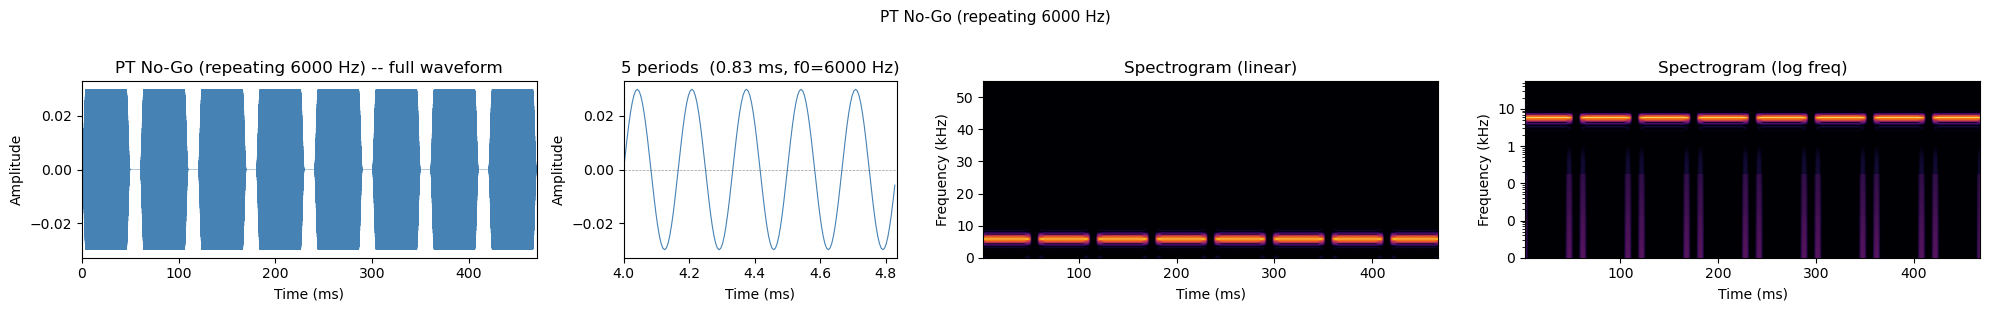

Duration: 470 ms | SR: 192 kHz


In [25]:
# PT No-Go: repeating pulse train, F0 = 6 kHz
pt_nogo = make_pulse_train([
    lambda: make_pure_tone(F0_NOGO, duration=PULSE_DUR, sr=SR, ramp=RAMP, amplitude=AMPLITUDE),
], pulse_dur=PULSE_DUR, pulse_onset=PULSE_ONSET, n_pulses=N_PULSES, sr=SR)
show(f'PT No-Go (repeating {F0_NOGO} Hz)', pt_nogo, sr=SR, ramp=RAMP, f0=F0_NOGO)

## Hard task -- Harmonic Complex Tones (HCT)

Equal-amplitude harmonics from F0 up to 50 kHz:

| F0 | Harmonic freqs (kHz) |
|----|-----------|
| 4.5 kHz | 4.5, 9.0, 13.5, 18.0, 22.5, 27.0, 31.5, 36.0, 40.5, 45.0, 49.5 (11 harmonics) |
| 7.9 kHz | 7.9, 15.8, 23.7, 31.6, 39.5, 47.4 (6 harmonics) |
| 6.0 kHz | 6, 12, 18, 24, 30, 36, 42, 48 (8 harmonics) |

In [26]:
# Verify harmonic content
for f0 in [F0_LOW, F0_HIGH, F0_NOGO]:
    harms = [k * f0 / 1000 for k in range(1, int(HCT_MAX_FREQ / f0) + 1)
             if k * f0 <= HCT_MAX_FREQ]
    print('F0=' + str(f0/1000) + ' kHz  (' + str(len(harms)) + ' harmonics):', harms, 'kHz')

F0=4.547 kHz  (10 harmonics): [4.547, 9.094, 13.641, 18.188, 22.735, 27.282, 31.829, 36.376, 40.923, 45.47] kHz
F0=7.917 kHz  (6 harmonics): [7.917, 15.834, 23.751, 31.668, 39.585, 47.502] kHz
F0=6.0 kHz  (8 harmonics): [6.0, 12.0, 18.0, 24.0, 30.0, 36.0, 42.0, 48.0] kHz


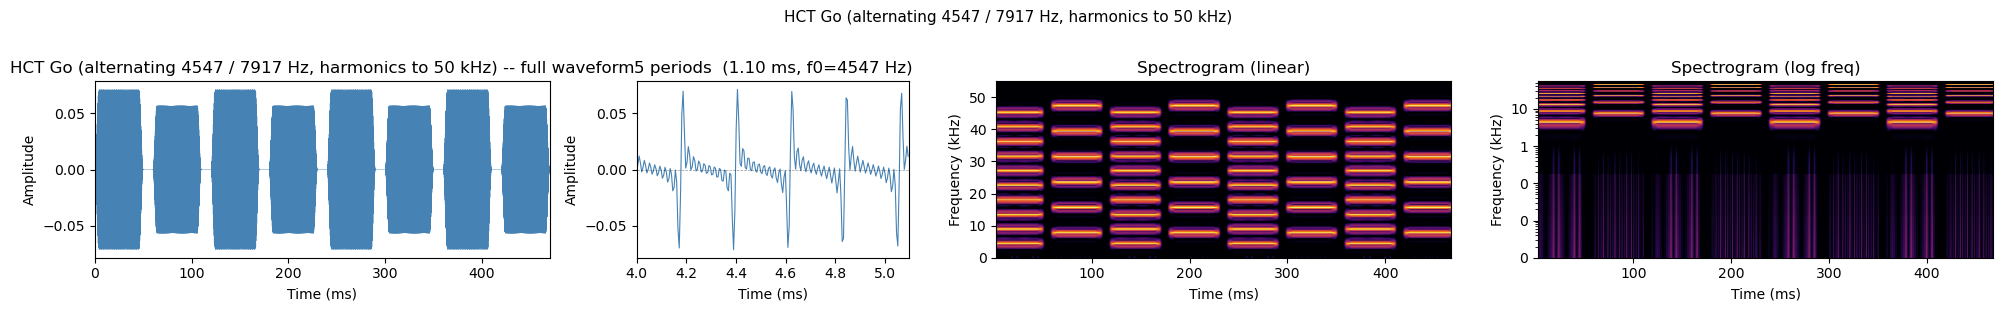

Duration: 470 ms | SR: 192 kHz


In [27]:
# HCT Go: alternating pulse train, F0 = 4.5 kHz / 7.9 kHz
hct_go = make_pulse_train([
    lambda: make_hct(F0_LOW,  duration=PULSE_DUR, sr=SR, max_freq=HCT_MAX_FREQ, ramp=RAMP, amplitude=AMPLITUDE, mask_f0=False),
    lambda: make_hct(F0_HIGH, duration=PULSE_DUR, sr=SR, max_freq=HCT_MAX_FREQ, ramp=RAMP, amplitude=AMPLITUDE, mask_f0=False),
], pulse_dur=PULSE_DUR, pulse_onset=PULSE_ONSET, n_pulses=N_PULSES, sr=SR)
show(f'HCT Go (alternating {F0_LOW} / {F0_HIGH} Hz, harmonics to {HCT_MAX_FREQ//1000} kHz)', hct_go, sr=SR, ramp=RAMP, f0=F0_LOW)

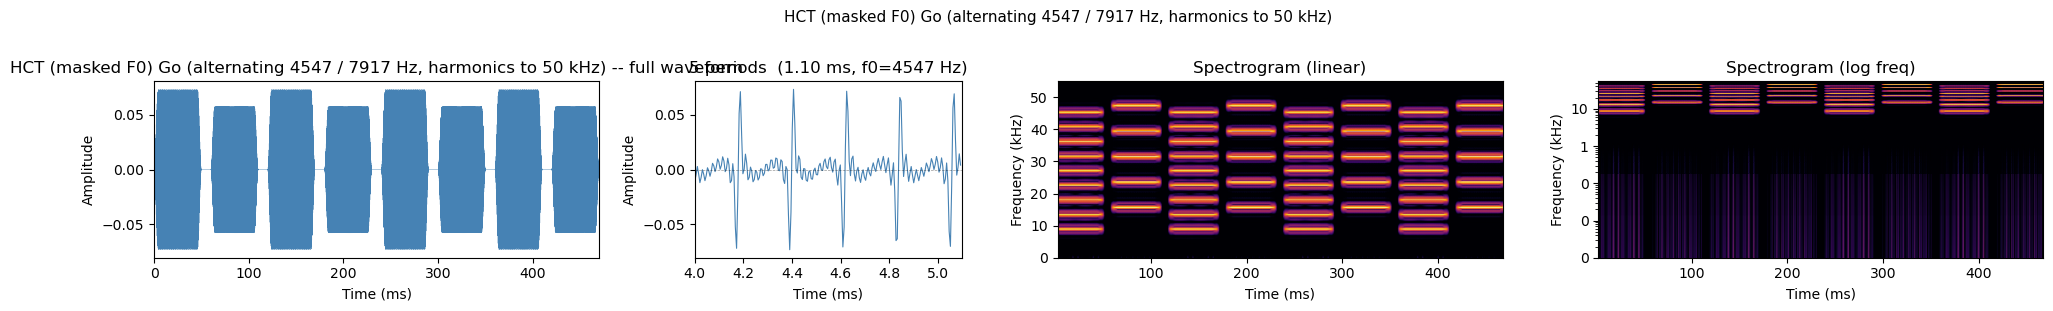

Duration: 470 ms | SR: 192 kHz


In [28]:
# HCT Go: alternating pulse train, F0 = 4.5 kHz / 7.9 kHz
hct_go = make_pulse_train([
    lambda: make_hct(F0_LOW, duration=PULSE_DUR, sr=SR, max_freq=HCT_MAX_FREQ, ramp=RAMP, amplitude=AMPLITUDE, mask_f0=True),
    lambda: make_hct(F0_HIGH, duration=PULSE_DUR, sr=SR, max_freq=HCT_MAX_FREQ, ramp=RAMP, amplitude=AMPLITUDE, mask_f0=True),
], pulse_dur=PULSE_DUR, pulse_onset=PULSE_ONSET, n_pulses=N_PULSES, sr=SR)
show(f'HCT (masked F0) Go (alternating {F0_LOW} / {F0_HIGH} Hz, harmonics to {HCT_MAX_FREQ//1000} kHz)', hct_go, sr=SR, ramp=RAMP, f0=F0_LOW)

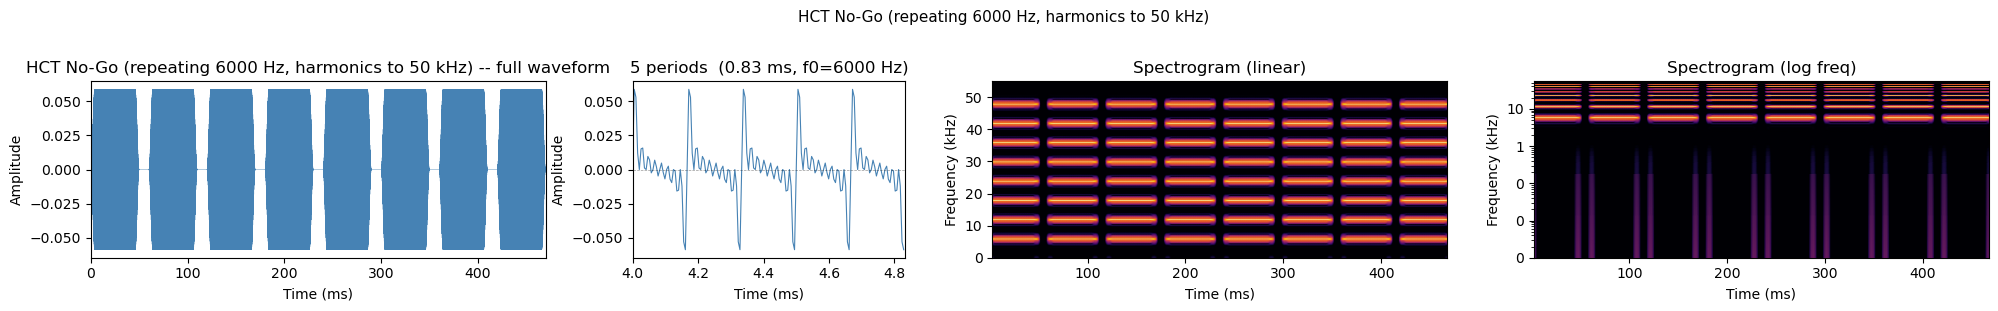

Duration: 470 ms | SR: 192 kHz


In [29]:
# HCT No-Go: repeating pulse train, F0 = 6 kHz
hct_nogo = make_pulse_train([
    lambda: make_hct(F0_NOGO, duration=PULSE_DUR, sr=SR, max_freq=HCT_MAX_FREQ, ramp=RAMP, amplitude=AMPLITUDE, mask_f0=False),
], pulse_dur=PULSE_DUR, pulse_onset=PULSE_ONSET, n_pulses=N_PULSES, sr=SR)
show(f'HCT No-Go (repeating {F0_NOGO} Hz, harmonics to {HCT_MAX_FREQ//1000} kHz)', hct_nogo, sr=SR, ramp=RAMP, f0=F0_NOGO)

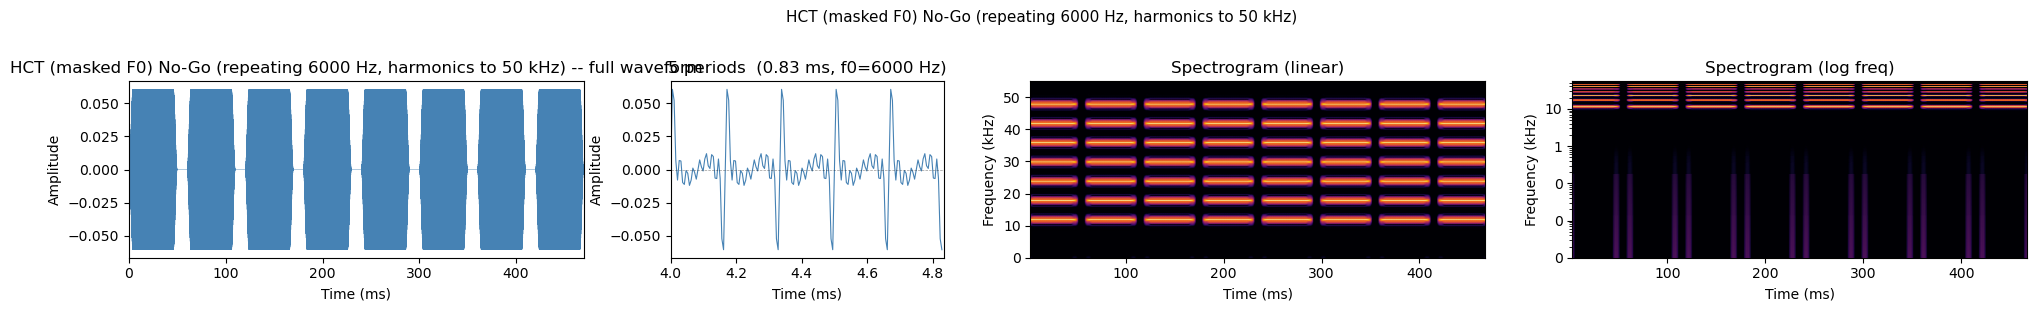

Duration: 470 ms | SR: 192 kHz


In [30]:
# HCT No-Go: repeating pulse train, F0 = 6 kHz
hct_nogo = make_pulse_train([
    lambda: make_hct(F0_NOGO, duration=PULSE_DUR, sr=SR, max_freq=HCT_MAX_FREQ, ramp=RAMP, amplitude=AMPLITUDE, mask_f0=True),
], pulse_dur=PULSE_DUR, pulse_onset=PULSE_ONSET, n_pulses=N_PULSES, sr=SR)
show(f'HCT (masked F0) No-Go (repeating {F0_NOGO} Hz, harmonics to {HCT_MAX_FREQ//1000} kHz)', hct_nogo, sr=SR, ramp=RAMP, f0=F0_NOGO)

## Save stimuli as WAV files

In [31]:
import scipy.io.wavfile, os

out_dir = '../stimuli'
os.makedirs(out_dir, exist_ok=True)

for name, wave in [('PT_Go', pt_go), ('PT_NoGo', pt_nogo),
                    ('HCT_Go', hct_go), ('HCT_NoGo', hct_nogo)]:
    pcm  = (wave / np.max(np.abs(wave)) * 32767).astype(np.int16)
    path = os.path.join(out_dir, name + '.wav')
    scipy.io.wavfile.write(path, SR, pcm)
    print('Saved', path)

Saved ../stimuli\PT_Go.wav
Saved ../stimuli\PT_NoGo.wav
Saved ../stimuli\HCT_Go.wav
Saved ../stimuli\HCT_NoGo.wav


## White Noise stimuli

Go: alternating pulses at **35 dB** and **45 dB** SPL  
No-Go: repeating pulses at **75 dB** SPL  
All other stimuli use 60 dB SPL (`AMPLITUDE = db_to_amp(60)`).

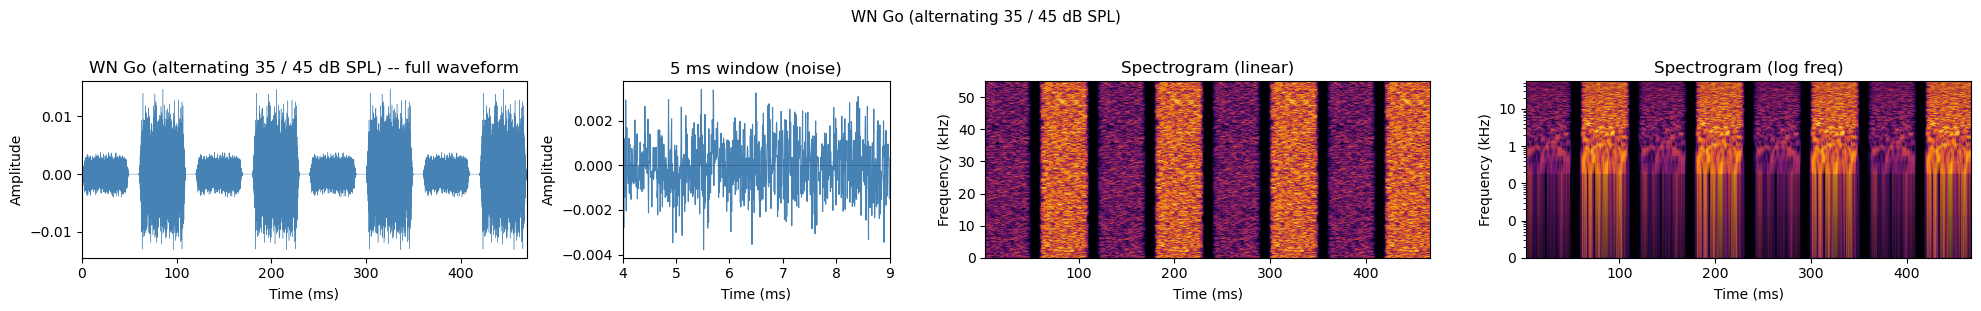

Duration: 470 ms | SR: 192 kHz


In [32]:
# White Noise Go: alternating 35 dB / 45 dB
wn_go = make_pulse_train([
    lambda: make_white_noise(duration=PULSE_DUR, sr=SR, ramp=RAMP, amplitude=db_to_amp(35), seed=0),
    lambda: make_white_noise(duration=PULSE_DUR, sr=SR, ramp=RAMP, amplitude=db_to_amp(45), seed=1),
], pulse_dur=PULSE_DUR, pulse_onset=PULSE_ONSET, n_pulses=N_PULSES, sr=SR)
show(f'WN Go (alternating 35 / 45 dB SPL)', wn_go, sr=SR, ramp=RAMP)

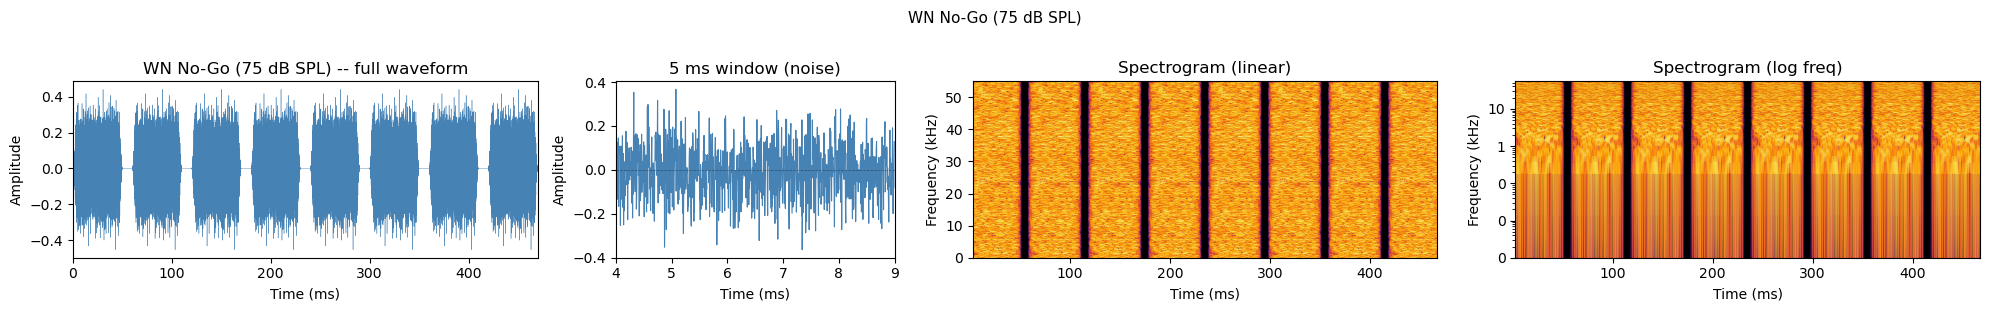

Duration: 470 ms | SR: 192 kHz


In [33]:
# White Noise No-Go: repeating 75 dB
wn_nogo = make_pulse_train([
    lambda: make_white_noise(duration=PULSE_DUR, sr=SR, ramp=RAMP, amplitude=db_to_amp(75), seed=2),
], pulse_dur=PULSE_DUR, pulse_onset=PULSE_ONSET, n_pulses=N_PULSES, sr=SR)
show(f'WN No-Go (75 dB SPL)', wn_nogo, sr=SR, ramp=RAMP)

## Tone spectra

Feature vector for each stimulus: `{frequency_hz: amplitude}`.  
White noise has no discrete frequency components â€” returns empty dict.

In [34]:
from utils.tone_utils import tone_spectrum

stimuli = [
    # label,               f0,      max_freq,     mask_f0,  amplitude_override
    ('PT  Go  low',        F0_LOW,  None,         False,    None),
    ('PT  Go  high',       F0_HIGH, None,         False,    None),
    ('PT  No-Go',          F0_NOGO, None,         False,    None),
    ('HCT Go  low',        F0_LOW,  HCT_MAX_FREQ, False,    None),
    ('HCT Go  high',       F0_HIGH, HCT_MAX_FREQ, False,    None),
    ('HCT No-Go',          F0_NOGO, HCT_MAX_FREQ, False,    None),
    ('WN  Go  (35 dB)',    None,    None,         False,    db_to_amp(35)),
    ('WN  Go  (45 dB)',    None,    None,         False,    db_to_amp(45)),
    ('WN  No-Go (75 dB)',  None,    None,         False,    db_to_amp(75)),
]

spectra = {}
for label, f0, max_freq, mask, amp_override in stimuli:
    amp = amp_override if amp_override is not None else AMPLITUDE
    if f0 is None:
        spectra[label] = {}   # white noise: broadband, no discrete components
    else:
        spectra[label] = tone_spectrum(
            f0, PULSE_DUR, SR, RAMP, amp,
            max_freq=max_freq, mask_f0=mask
        )

for label, spec in spectra.items():
    if spec:
        entries = ', '.join('{:.0f} Hz: {:.4f}'.format(f, a) for f, a in spec.items())
        print('{:<22} ({} components)'.format(label, len(spec)))
        print('  ', entries)
    else:
        print('{:<22} -- broadband noise, no discrete components'.format(label))
    print()


PT  Go  low            (1 components)
   4547 Hz: 0.0200

PT  Go  high           (1 components)
   7917 Hz: 0.0200

PT  No-Go              (1 components)
   6000 Hz: 0.0200

HCT Go  low            (10 components)
   4547 Hz: 0.0026, 9094 Hz: 0.0026, 13641 Hz: 0.0026, 18188 Hz: 0.0026, 22735 Hz: 0.0026, 27282 Hz: 0.0026, 31829 Hz: 0.0026, 36376 Hz: 0.0026, 40923 Hz: 0.0026, 45470 Hz: 0.0026

HCT Go  high           (6 components)
   7917 Hz: 0.0043, 15834 Hz: 0.0043, 23751 Hz: 0.0043, 31668 Hz: 0.0043, 39585 Hz: 0.0043, 47502 Hz: 0.0043

HCT No-Go              (8 components)
   6000 Hz: 0.0036, 12000 Hz: 0.0036, 18000 Hz: 0.0036, 24000 Hz: 0.0036, 30000 Hz: 0.0036, 36000 Hz: 0.0036, 42000 Hz: 0.0036, 48000 Hz: 0.0036

WN  Go  (35 dB)        -- broadband noise, no discrete components

WN  Go  (45 dB)        -- broadband noise, no discrete components

WN  No-Go (75 dB)      -- broadband noise, no discrete components



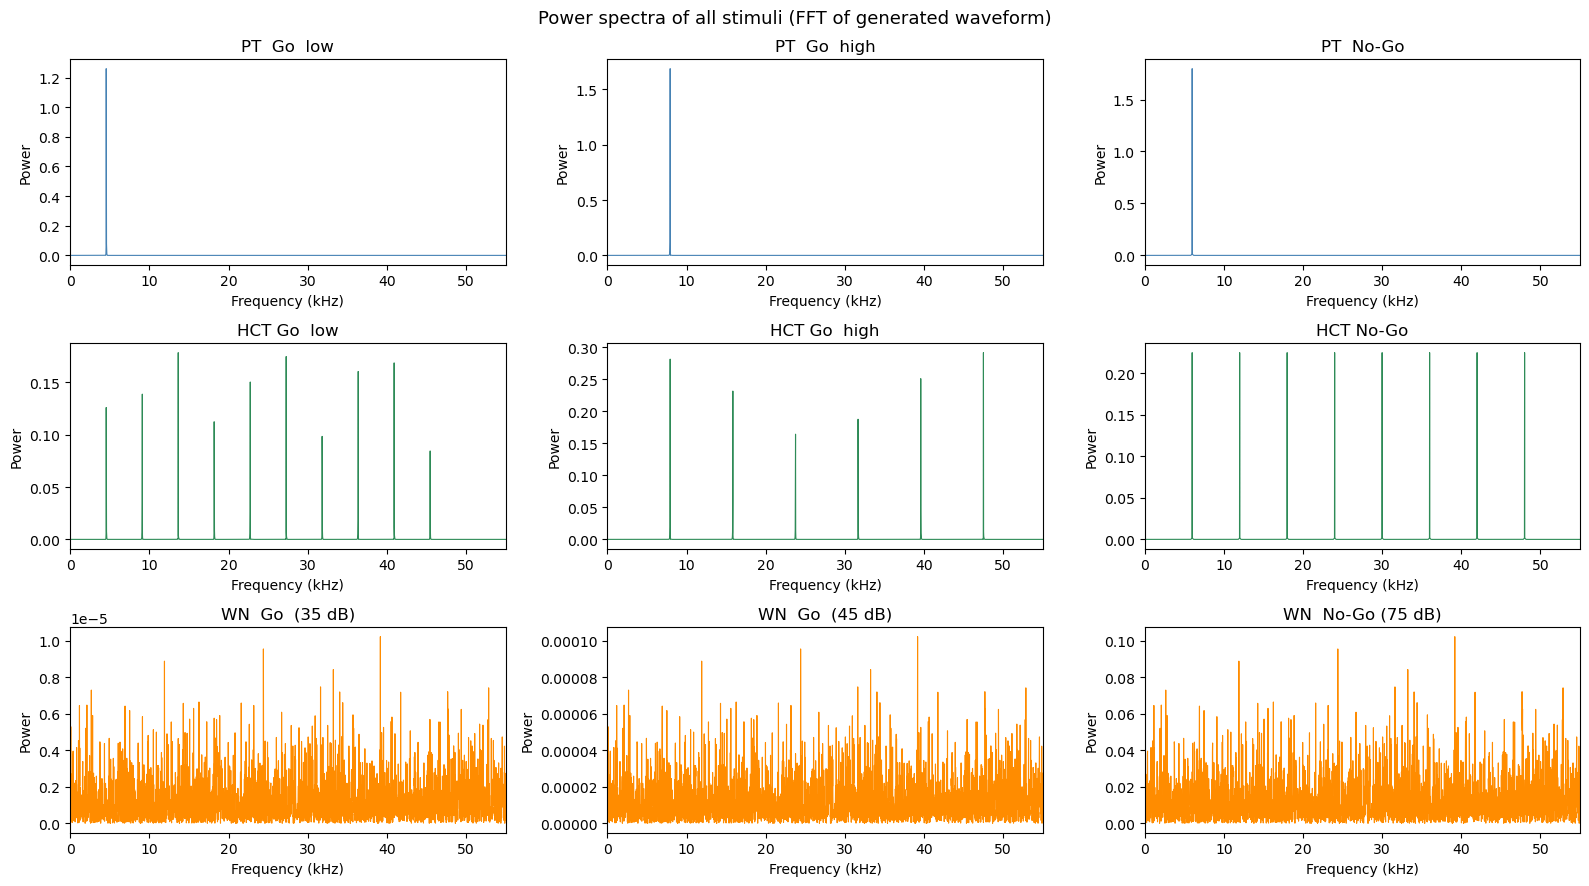

In [35]:
from utils.tone_utils import tone_fft

all_stimuli = [
    ('PT  Go  low',        F0_LOW,  None,         False, AMPLITUDE),
    ('PT  Go  high',       F0_HIGH, None,         False, AMPLITUDE),
    ('PT  No-Go',          F0_NOGO, None,         False, AMPLITUDE),
    ('HCT Go  low',        F0_LOW,  HCT_MAX_FREQ, False, AMPLITUDE),
    ('HCT Go  high',       F0_HIGH, HCT_MAX_FREQ, False, AMPLITUDE),
    ('HCT No-Go',          F0_NOGO, HCT_MAX_FREQ, False, AMPLITUDE),
    ('WN  Go  (35 dB)',    None,    None,         False, db_to_amp(35)),
    ('WN  Go  (45 dB)',    None,    None,         False, db_to_amp(45)),
    ('WN  No-Go (75 dB)',  None,    None,         False, db_to_amp(75)),
]

color_map = {'PT': 'steelblue', 'HCT': 'seagreen', 'WN': 'darkorange'}

fig, axes = plt.subplots(3, 3, figsize=(16, 9))

for ax, (label, f0, max_freq, mask, amp) in zip(axes.flat, all_stimuli):
    result   = tone_fft(f0, PULSE_DUR, SR, RAMP, amp,
                        max_freq=max_freq, mask_f0=mask, seed=42)
    freq_khz = result['freq'] / 1000
    power    = result['power']
    vis      = freq_khz <= 55
    color    = color_map[label[:3].strip()]
    ax.plot(freq_khz[vis], power[vis], lw=0.8, color=color)
    ax.set(xlabel='Frequency (kHz)', ylabel='Power',
           title=label, xlim=(0, 55))

plt.suptitle('Power spectra of all stimuli (FFT of generated waveform)', fontsize=13)
plt.tight_layout()
plt.show()


In [36]:
from scipy.signal import find_peaks

results = {}

PULSE_DUR = 1

for label, f0, max_freq, mask, amp in all_stimuli:
    result = tone_fft(f0, PULSE_DUR, SR, RAMP, amp,
                      max_freq=max_freq, mask_f0=mask, seed=42,
                      theoretical=(f0 is None), round_to=1)
    power = result['power']
    freq  = result['freq']

    if f0 is None:
        # White noise: flat theoretical spectrum, no discrete peaks
        results[label] = {'freqs': np.array([]), 'power': np.array([])}
        print('{:<22} broadband noise, flat power = {:.6f}'.format(label, power[0]))
    else:
        threshold = power.mean() + 2 * power.std()
        peak_idxs, _ = find_peaks(power, height=threshold)
        results[label] = {'freqs': freq[peak_idxs], 'power': power[peak_idxs]}
        freqs_khz = freq[peak_idxs] / 1000
        entries   = ', '.join('{:.2f} kHz ({:.4f})'.format(f, p)
                              for f, p in zip(freqs_khz, power[peak_idxs]))
        print('{:<22} {} peaks: {}'.format(label, len(freqs_khz), entries))

PT  Go  low            1 peaks: 4.55 kHz (38.1035)
PT  Go  high           1 peaks: 7.92 kHz (38.1035)
PT  No-Go              1 peaks: 6.00 kHz (38.1035)
HCT Go  low            10 peaks: 4.55 kHz (3.8103), 9.09 kHz (3.8103), 13.64 kHz (3.8103), 18.19 kHz (3.8103), 22.73 kHz (3.8103), 27.28 kHz (3.8103), 31.83 kHz (3.8103), 36.38 kHz (3.8103), 40.92 kHz (3.8103), 45.47 kHz (3.8103)
HCT Go  high           6 peaks: 7.92 kHz (6.3506), 15.83 kHz (6.3506), 23.75 kHz (6.3506), 31.67 kHz (6.3506), 39.59 kHz (6.3506), 47.50 kHz (6.3506)
HCT No-Go              8 peaks: 6.00 kHz (4.7629), 12.00 kHz (4.7629), 18.00 kHz (4.7629), 24.00 kHz (4.7629), 30.00 kHz (4.7629), 36.00 kHz (4.7629), 42.00 kHz (4.7629), 48.00 kHz (4.7629)
WN  Go  (35 dB)        broadband noise, flat power = 0.000001
WN  Go  (45 dB)        broadband noise, flat power = 0.000013
WN  No-Go (75 dB)      broadband noise, flat power = 0.012589


In [45]:
freq_thresh = 10  # % — max allowed relative distance from a peak to its nearest grid point

# Build log grid from tonal peaks only
tonal_freqs = np.concatenate([results[label]['freqs']
                               for label in results
                               if len(results[label]['freqs']) > 0])
tonal_freqs = np.unique(tonal_freqs)

freq_min   = tonal_freqs.min()
freq_max   = tonal_freqs.max()
grid_ratio = 1 + freq_thresh / 100
n_grid     = int(np.ceil(np.log(freq_max / freq_min) / np.log(grid_ratio))) + 1
grid       = freq_min * grid_ratio ** np.arange(n_grid)
log_grid   = np.log(grid)

max_pct = max(np.min(np.abs(log_grid - np.log(f))) / np.log(1 + freq_thresh / 100) * freq_thresh
              for f in tonal_freqs)
print('Grid: {:.0f} – {:.0f} Hz, ratio {:.3f}, {} points'.format(
      freq_min, freq_max, grid_ratio, n_grid))
print('Max snap distance: {:.2f}% (threshold: {}%)'.format(max_pct, freq_thresh))

# Reference: mean total power of tonal stimuli at 60 dB
tonal_total_powers = [results[label]['power'].sum()
                      for label in results
                      if len(results[label]['power']) > 0]
ref_power = np.mean(tonal_total_powers)   # corresponds to AMPLITUDE = db_to_amp(60)

# Build results_wnaligned
results_wnaligned = {}
for label, f0, max_freq, mask, amp in all_stimuli:
    if f0 is None:
        # Scale WN total power by (amp / AMPLITUDE)^2 relative to tonal reference,
        # then spread flat across log grid bins
        wn_total     = ref_power * (amp / AMPLITUDE) ** 2
        wn_flat_power = wn_total / n_grid
        results_wnaligned[label] = {
            'freqs': grid.copy(),
            'power': np.full(n_grid, wn_flat_power)
        }
    else:
        orig_freqs = results[label]['freqs']
        orig_power = results[label]['power']
        snap_idx   = np.argmin(np.abs(log_grid[:, None] - np.log(orig_freqs)[None, :]), axis=0)
        results_wnaligned[label] = {
            'freqs': grid[snap_idx],
            'power': orig_power
        }

for label, res in results_wnaligned.items():
    print('{:<22} {} bins, total power = {:.6f}'.format(
          label, len(res['freqs']), res['power'].sum()))

Grid: 4547 – 48000 Hz, ratio 1.100, 26 points
Max snap distance: 4.73% (threshold: 10%)
PT  Go  low            1 bins, total power = 38.103473
PT  Go  high           1 bins, total power = 38.103473
PT  No-Go              1 bins, total power = 38.103473
HCT Go  low            10 bins, total power = 38.103473
HCT Go  high           6 bins, total power = 38.103473
HCT No-Go              8 bins, total power = 38.103473
WN  Go  (35 dB)        26 bins, total power = 0.120494
WN  Go  (45 dB)        26 bins, total power = 1.204938
WN  No-Go (75 dB)      26 bins, total power = 1204.937613


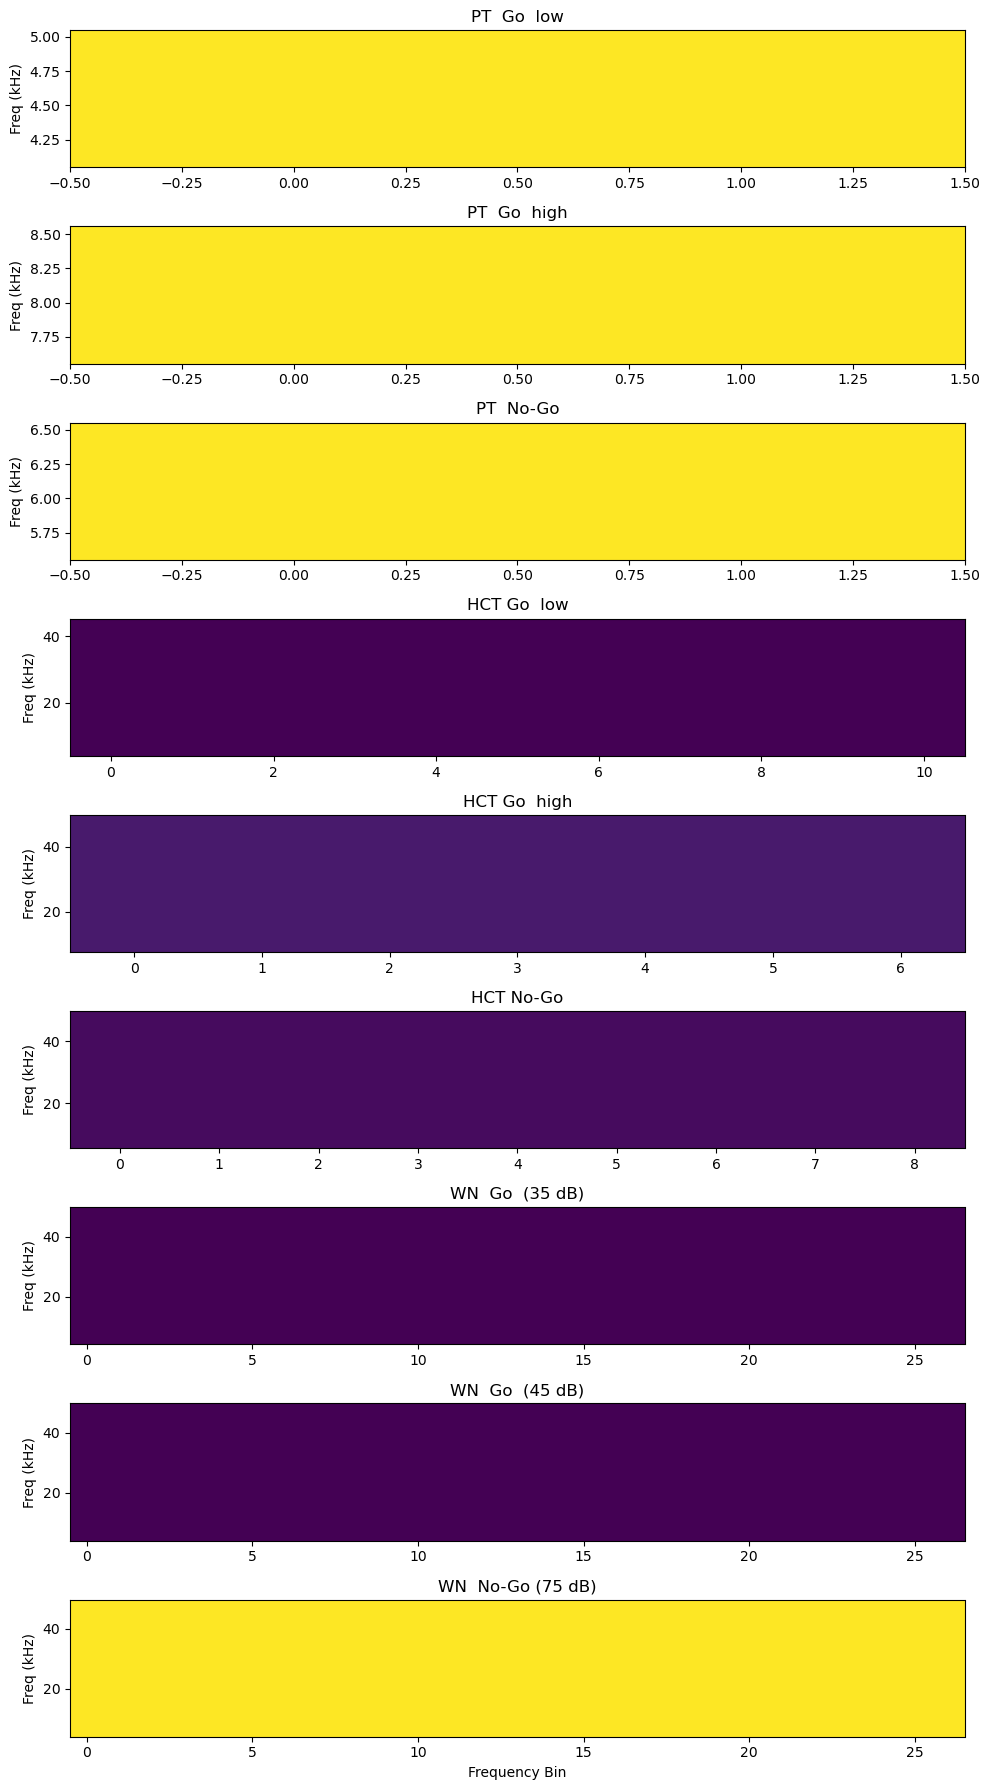

In [46]:
# plot as color map
import matplotlib.pyplot as plt

tonal_pows = [results_wnaligned[label]['power'] for label in results_wnaligned
              if len(results[label]['power']) > 0]   # colour scale from tonal peaks only
vmin = min(p.min() for p in tonal_pows)
vmax = max(p.max() for p in tonal_pows)

fig, axes = plt.subplots(len(results_wnaligned), 1, figsize=(10, 2*len(results_wnaligned)))
for ax, label in zip(axes, results_wnaligned):
    freqs_khz = results_wnaligned[label]['freqs'] / 1000
    pows      = results_wnaligned[label]['power']
    ax.imshow(pows.reshape(1, -1), aspect='auto',
              extent=[0-0.5, len(freqs_khz)+0.5, freqs_khz.min()-0.5, freqs_khz.max()+0.5],
              origin='lower', cmap='viridis', vmin=vmin, vmax=vmax)
    ax.set_ylabel('Freq (kHz)')
    ax.set_title(label)
axes[-1].set_xlabel('Frequency Bin')
plt.tight_layout()
plt.show()

In [47]:
# gather all frequencies from results_wnaligned
all_freqs = np.unique(np.concatenate([results_wnaligned[label]['freqs']
                                       for label in results_wnaligned]))

In [48]:
# feature vector for each stimulus: log1p(power) at each frequency in all_freqs
all_vectors = {}
tol = 5
for label in results_wnaligned:
    vector = np.zeros(len(all_freqs))
    freqs  = results_wnaligned[label]['freqs']
    pows   = results_wnaligned[label]['power']
    for f, p in zip(freqs, pows):
        idx = np.searchsorted(all_freqs, f)
        if idx < len(all_freqs) and abs(all_freqs[idx] - f) <= tol:
            vector[idx] = p
    all_vectors[label] = np.log1p(vector)

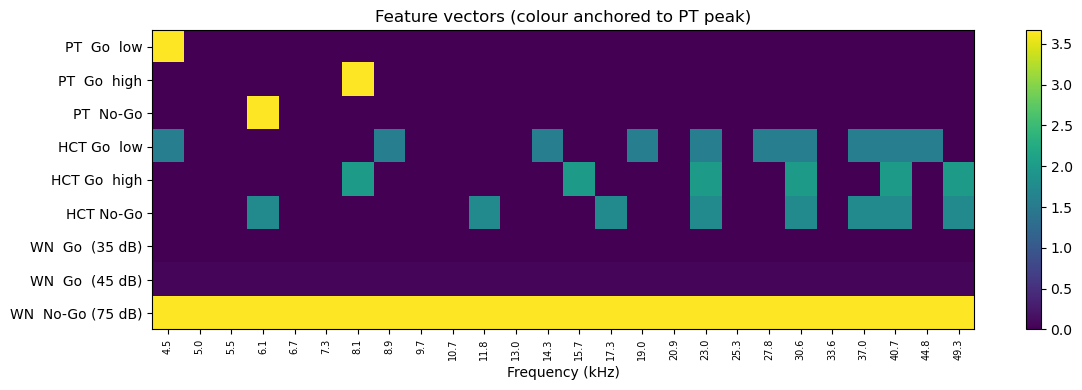

Per-stimulus max and sum:
  PT  Go  low             max=3.6662  sum=3.6662
  PT  Go  high            max=3.6662  sum=3.6662
  PT  No-Go               max=3.6662  sum=3.6662
  HCT Go  low             max=1.5708  sum=15.7077
  HCT Go  high            max=1.9948  sum=11.9687
  HCT No-Go               max=1.7514  sum=14.0116
  WN  Go  (35 dB)         max=0.0046  sum=0.1202
  WN  Go  (45 dB)         max=0.0453  sum=1.1779
  WN  No-Go (75 dB)       max=3.8574  sum=100.2933


In [49]:
mat    = np.array(list(all_vectors.values()))
labels = list(all_vectors.keys())
xticks = ['{:.1f}'.format(f / 1000) for f in all_freqs]

# Anchor colour scale to PT peak so WN bins are visible in context
pt_max = max(all_vectors[l].max() for l in all_vectors if l.startswith('PT'))
vmin, vmax = 0, pt_max

fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(mat, aspect='auto', cmap='viridis', vmin=vmin, vmax=vmax)
ax.set_xticks(np.arange(len(all_freqs)))
ax.set_xticklabels(xticks, rotation=90, fontsize=7)
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels)
ax.set_xlabel('Frequency (kHz)')
ax.set_title('Feature vectors (colour anchored to PT peak)')
plt.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

print('Per-stimulus max and sum:')
for label, v in all_vectors.items():
    print('  {:<22}  max={:.4f}  sum={:.4f}'.format(label, v.max(), v.sum()))

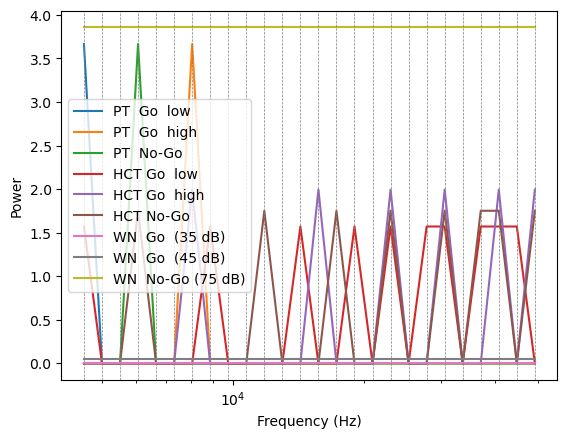

In [50]:
# plot each vector in log scale in frequency
fig, ax = plt.subplots()
for label in all_vectors:
    ax.plot(all_freqs, all_vectors[label], label=label)

# plot grid for all_freqs
for f in all_freqs:
    ax.axvline(f, color='gray', linestyle='--', linewidth=0.5)

ax.set_xscale('log')
ax.set_xlabel('Frequency (Hz)')
ax.set_ylabel('Power')
ax.legend()
plt.show()

In [51]:
all_vectors['WN  Go  (35 dB)']

array([0.00462367, 0.00462367, 0.00462367, 0.00462367, 0.00462367,
       0.00462367, 0.00462367, 0.00462367, 0.00462367, 0.00462367,
       0.00462367, 0.00462367, 0.00462367, 0.00462367, 0.00462367,
       0.00462367, 0.00462367, 0.00462367, 0.00462367, 0.00462367,
       0.00462367, 0.00462367, 0.00462367, 0.00462367, 0.00462367,
       0.00462367])